# Do Deadlock balance patches actually work?

**Question.** When Valve buffs or nerfs a Deadlock hero, does the hero's win rate (and pick rate) change by more than it normally drifts week to week, and in the intended direction?

**Why it's not trivial.** Win rates move constantly: other heroes get changed, players learn, the population shifts. A naive "7 days before vs 7 days after" comparison mixes the patch effect with all of that. And with 100k+ matches a week, a textbook binomial confidence interval is so narrow that almost *any* change looks "statistically significant", even though real week-to-week noise is far larger.

**Data.**
- Daily wins and matches per hero for about 13 months, from the community [deadlock-api.com](https://deadlock-api.com) match database. This is collected daily by this project's GitHub Action (`pipeline/deadlock_heroes.py`).
- A hand-curated patch history: which heroes each patch buffed, nerfed, reworked or adjusted (`data/deadlock/patch-notes.curated.json`).

The analysis code lives in `pipeline/patch_impact.py`, which also feeds the site's *Patch impact* page. This notebook walks through it step by step.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
sys.path.insert(0, str(ROOT / "pipeline"))
import patch_impact as pi

# Chart styling: validated categorical palette (blue / orange), plus fixed buff/nerf colors.
BLUE, ORANGE, GRAY, BUFF, NERF = "#2a78d6", "#eb6834", "#898781", "#008300", "#d03b3b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "font.family": "sans-serif", "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.precision", 2)

## 1. The data

In [2]:
daily, events, placebo = pi.run()
print(f"{daily['hero'].nunique()} heroes x {daily['date'].nunique()} days "
      f"({daily['date'].min():%b %d, %Y} to {daily['date'].max():%b %d, %Y}), "
      f"{daily['matches'].sum()/12/1e6:.1f}M matches")
daily.head()

44 heroes x 400 days (Oct 16, 2025 to Nov 19, 2026), 27.2M matches


,date,hero,role,wins,matches,total
0,2025-10-16,Abrams,Brawler,7299,14189,36926
1,2025-10-17,Abrams,Brawler,7184,13906,36318
2,2025-10-18,Abrams,Brawler,7402,14462,38131
3,2025-10-19,Abrams,Brawler,7805,14874,39869
4,2025-10-20,Abrams,Brawler,6830,13054,35827


In [3]:
changes = pi.load_changes()
print(f"{changes['patch_date'].nunique()} patches with hero changes, {len(changes)} hero changes in total")
changes["type"].value_counts().rename("hero changes").to_frame()

45 patches with hero changes, 435 hero changes in total


,hero changes
type,
nerf,178
buff,174
adjustment,69
new,12
rework,2


## 2. Method

For each (patch, hero) change:

1. **Before / after.** Match-weighted win rate (and pick rate) for the 7 days before vs the 7 days after. The patch day itself is skipped, since it's split between versions.
2. **Difference-in-differences (DiD).** Subtract the average change of heroes *not* changed within 7 days of that patch. Everything that hit all heroes at once (other changes, new players, events) cancels out.
3. **Noise baseline (placebo test).** Run the identical calculation on every day where a hero had *no* change within ±14 days. Each hero gets their own distribution of "normal" week-over-week DiD swings, and the patch effect is compared to it.
4. **Significance.** Empirical two-sided p-value: the share of that hero's placebo swings at least as large as the observed one. Then a **Benjamini–Hochberg** correction across all events, because we run hundreds of tests (false discovery rate 10%).

Excluded: hero releases (no "before"), and changes where the same hero was patched again within 7 days (effects can't be separated).

In [4]:
print("Event status:")
print(events["status"].value_counts().to_string())

Event status:
status
ok                             319
changed again within 7 days    104
release (no before window)      12


### Why not a normal confidence interval?
Compare the binomial standard error with how much win rates *actually* move on days when nothing happened to the hero:

In [5]:
ok = events[events["status"].eq("ok")].copy()
p = ok["wr_before"] / 100
binom_se = 100 * np.sqrt(p * (1 - p) / ok["n_before"] + p * (1 - p) / ok["n_after"])
print(f"Typical binomial SE of a 7-vs-7-day change: {binom_se.median():.2f} pts")
print(f"Typical real (placebo) SD of the same change: {ok['noise_sd_wr'].median():.2f} pts")
print(f"-> real noise is about {ok['noise_sd_wr'].median() / binom_se.median():.0f}x larger than the binomial model assumes")

Typical binomial SE of a 7-vs-7-day change: 0.21 pts
Typical real (placebo) SD of the same change: 0.64 pts
-> real noise is about 3x larger than the binomial model assumes


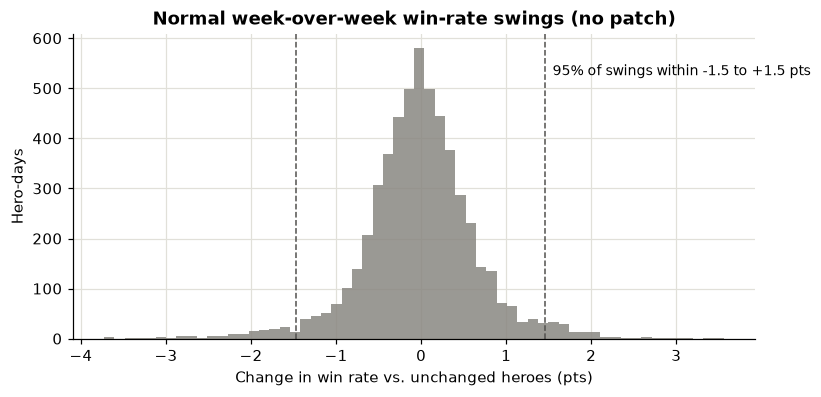

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.hist(placebo["did_wr"], bins=60, color=GRAY, alpha=0.85)
lo, hi = placebo["did_wr"].quantile([0.025, 0.975])
for v in (lo, hi):
    ax.axvline(v, color="#52514e", ls="--", lw=1)
ax.set_title("Normal week-over-week win-rate swings (no patch)")
ax.set_xlabel("Change in win rate vs. unchanged heroes (pts)")
ax.set_ylabel("Hero-days")
ax.text(hi, ax.get_ylim()[1] * 0.9, f"  95% of swings within {lo:+.1f} to {hi:+.1f} pts", va="top", fontsize=9)
plt.show()

## 3. Results

In [7]:
summary = pi.summarize(events, placebo)
rows = []
for t in ("buff", "nerf"):
    for k, label in (("wr", "Win rate"), ("pr", "Pick rate")):
        s = summary[t][k]
        rows.append({"change": t, "metric": label, "events": summary[t]["events"],
                     "mean effect (pts)": s["mean_effect"], "95% CI": f"{s['ci95'][0]:+.2f} to {s['ci95'][1]:+.2f}",
                     "moved the intended way": f"{s['share_expected_direction']:.0%}",
                     "significant (FDR 10%)": f"{s['significant']} ({s['significant_opposite']} wrong way)"})
pd.DataFrame(rows)

,change,metric,events,mean effect (pts),95% CI,moved the intended way,significant (FDR 10%)
0,buff,Win rate,136,0.80,+0.53 to +1.06,72%,37 (4 wrong way)
1,buff,Pick rate,136,3.56,+2.66 to +4.40,84%,51 (3 wrong way)
2,nerf,Win rate,129,-1.34,-1.58 to -1.11,84%,47 (0 wrong way)
3,nerf,Pick rate,129,-3.80,-4.61 to -3.03,81%,46 (2 wrong way)


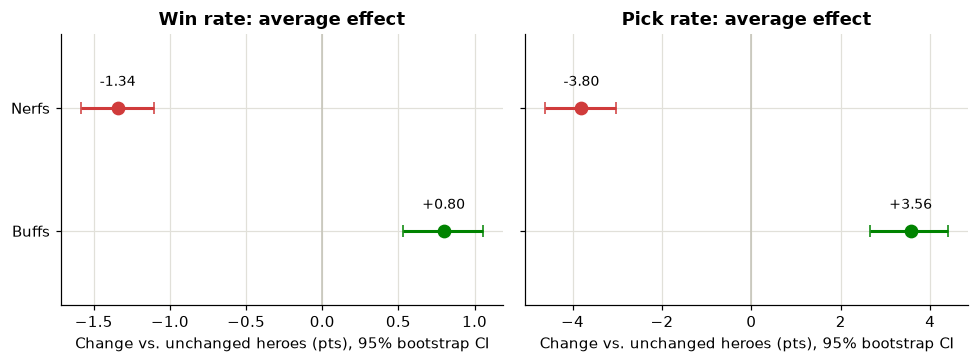

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, (k, title) in zip(axes, (("wr", "Win rate"), ("pr", "Pick rate"))):
    for i, (t, color) in enumerate((("buff", BUFF), ("nerf", NERF))):
        s = summary[t][k]
        ax.errorbar(s["mean_effect"], i, xerr=[[s["mean_effect"] - s["ci95"][0]], [s["ci95"][1] - s["mean_effect"]]],
                    fmt="o", color=color, ms=8, capsize=4, lw=2)
        ax.text(s["mean_effect"], i + 0.18, f"{s['mean_effect']:+.2f}", ha="center", fontsize=9)
    ax.axvline(0, color="#c3c2b7", lw=1)
    ax.set_title(f"{title}: average effect")
    ax.set_xlabel("Change vs. unchanged heroes (pts), 95% bootstrap CI")
axes[0].set_yticks([0, 1], ["Buffs", "Nerfs"])
axes[0].set_ylim(-0.6, 1.6)
plt.tight_layout(); plt.show()

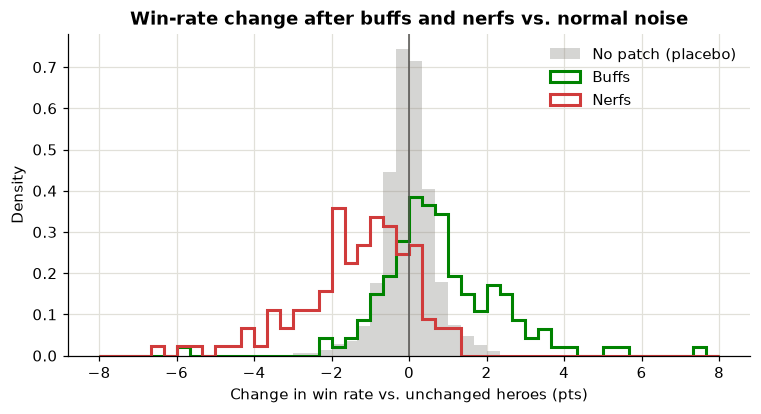

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.linspace(-8, 8, 49)
ax.hist(placebo["did_wr"], bins=bins, density=True, color=GRAY, alpha=0.35, label="No patch (placebo)")
for t, color in (("buff", BUFF), ("nerf", NERF)):
    ax.hist(ok.loc[ok["type"] == t, "did_wr"], bins=bins, density=True, histtype="step", lw=2, color=color, label=t.title() + "s")
ax.axvline(0, color="#52514e", lw=1)
ax.set_title("Win-rate change after buffs and nerfs vs. normal noise")
ax.set_xlabel("Change in win rate vs. unchanged heroes (pts)"); ax.set_ylabel("Density")
ax.legend(frameon=False); plt.show()

### Robustness: regression to the mean
Developers buff heroes that are doing badly and nerf heroes that are doing well. Heroes far from 50% might drift back on their own, which would fake a buff/nerf effect. Fit that drift on the placebo days:

In [10]:
mr = summary["mean_reversion"]
print(f"Placebo drift model: change = {mr['alpha']:+.3f} + {mr['beta']:+.4f} x (win rate before - 50)")
pd.DataFrame({t: {"avg win rate before patch": mr[t]["mean_pre_wr"], "drift expected from reversion": mr[t]["expected_drift"],
                  "measured effect": mr[t]["effect_raw"], "effect after removing drift": mr[t]["effect_adjusted"]}
              for t in ("buff", "nerf")}).T

Placebo drift model: change = -0.019 + -0.0089 x (win rate before - 50)


,avg win rate before patch,drift expected from reversion,measured effect,effect after removing drift
buff,49.33,-0.01,0.80,0.81
nerf,50.65,-0.02,-1.34,-1.32


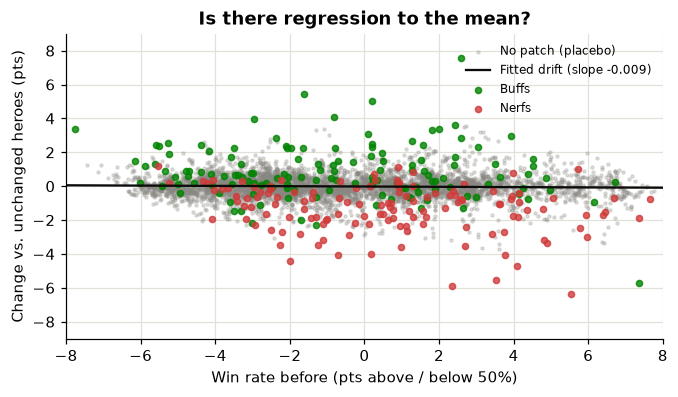

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.scatter(placebo["wr_before"] - 50, placebo["did_wr"], s=4, color=GRAY, alpha=0.25, label="No patch (placebo)")
x = np.linspace(-8, 8, 2)
ax.plot(x, mr["alpha"] + mr["beta"] * x, color="#0b0b0b", lw=1.5, label=f"Fitted drift (slope {mr['beta']:+.3f})")
for t, color in (("buff", BUFF), ("nerf", NERF)):
    g = ok[ok["type"] == t]
    ax.scatter(g["wr_before"] - 50, g["did_wr"], s=16, color=color, alpha=0.8, label=t.title() + "s")
ax.set_xlim(-8, 8); ax.set_ylim(-9, 9)
ax.set_xlabel("Win rate before (pts above / below 50%)"); ax.set_ylabel("Change vs. unchanged heroes (pts)")
ax.set_title("Is there regression to the mean?"); ax.legend(frameon=False, fontsize=8, loc="upper right")
plt.show()

## 4. The biggest individual effects

In [12]:
sig = ok[ok["sig_wr"].fillna(False)].copy()
sig["abs"] = sig["did_wr"].abs()
top = sig.sort_values("abs", ascending=False).head(15)
top[["patch_date", "hero", "type", "wr_before", "wr_after", "did_wr", "noise_sd_wr", "q_wr", "expected_wr"]].rename(columns={
    "patch_date": "patch", "wr_before": "WR before", "wr_after": "WR after", "did_wr": "effect (pts)",
    "noise_sd_wr": "hero's normal swing (SD)", "q_wr": "q-value", "expected_wr": "intended direction"})

,patch,hero,type,WR before,WR after,effect (pts),hero's normal swing (SD),q-value,intended direction
178,2026-05-22,Graves,buff,52.59,59.79,7.54,0.45,0.05,True
210,2026-04-30,Infernus,nerf,55.54,49.63,-6.36,0.56,0.05,True
314,2026-03-06,Kelvin,adjustment,46.02,51.13,6.03,0.51,0.05,False
230,2026-04-10,Haze,buff,57.37,51.89,-5.70,0.87,0.05,False
66,2026-09-16,Warden,nerf,53.53,48.15,-5.53,0.71,0.05,True
315,2026-03-06,Lady Geist,buff,48.38,52.92,5.47,0.70,0.05,True
123,2026-06-30,Drifter,buff,50.21,54.99,5.05,0.48,0.05,True
380,2025-12-30,McGinnis,adjustment,55.36,50.38,-4.79,0.75,0.05,False
77,2026-08-12,McGinnis,nerf,54.10,49.67,-4.69,0.75,0.05,True
186,2026-05-22,Mina,adjustment,49.26,44.45,-4.47,0.69,0.05,False


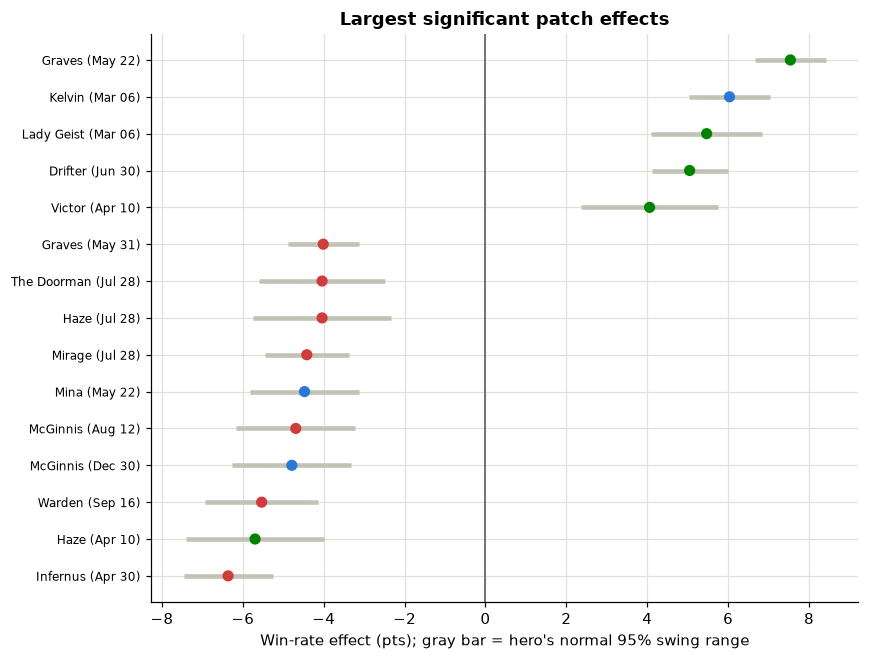

In [13]:
f = top.sort_values("did_wr")
fig, ax = plt.subplots(figsize=(8, 0.34 * len(f) + 1))
y = np.arange(len(f))
colors = [BUFF if t == "buff" else NERF if t == "nerf" else BLUE for t in f["type"]]
ax.errorbar(f["did_wr"], y, xerr=1.96 * f["noise_sd_wr"], fmt="none", ecolor="#c3c2b7", lw=3)
ax.scatter(f["did_wr"], y, color=colors, s=40, zorder=3)
ax.set_yticks(y, [f"{h} ({d:%b %d})" for h, d in zip(f["hero"], f["patch_date"])], fontsize=8)
ax.axvline(0, color="#52514e", lw=1)
ax.set_xlabel("Win-rate effect (pts); gray bar = hero's normal 95% swing range")
ax.set_title("Largest significant patch effects")
plt.tight_layout(); plt.show()

## 5. Conclusions

The numbers above are recomputed every time the notebook runs. As of the latest run:

- **Patches work, and nerfs hit harder than buffs.** The average nerf cut win rate by about **1.3 points**, and the average buff added about **0.8**. Both 95% bootstrap intervals exclude zero.
- **Nerfs are also more reliable.** Roughly **84%** of nerfs moved win rate down, against about **72%** of buffs moving it up. No significant nerf went the wrong way.
- **Pick rate reacts more than win rate.** Players respond to patch notes: buffs add about **3.6 points** of pick rate and nerfs remove about **3.8**. Pick rate is the clearer signal of *perceived* strength.
- **Most individual changes are within normal noise.** Only about a quarter to a third of single hero changes clear the bar after the multiple-testing correction. A 1-point "after" difference for one hero usually means nothing.
- **Not an artifact of regression to the mean.** Deadlock patches heroes that sit close to 50% (buffed about 49.3%, nerfed about 50.6%), and placebo drift barely depends on starting win rate, so the adjusted effects are essentially unchanged.

**Limitations**
- The data is a large *sample* of public matches, not all matches.
- The 7-day windows can include unrelated events, which is why the control group is there.
- Buff/nerf labels for older patches were classified from patch-note wording.
- 104 changes were excluded because the same hero was patched again within a week. Valve iterates fast, which limits clean before/after windows.
- This is observational: it shows what changed after patches, not a randomized test.